# 09 · Results

How much does the model actually save, and how sure can I be?

**Key takeaways**
1. **Starting 30–60 days out, the model saves 4.5% per trip on average**
   (95% CI 4.1–4.9%), or **6.7% of total spend** (about $9 per trip), and
   loses money on only 4% of trips. These are honest walk-forward results
   over about 49,000 trip decisions.
2. Savings are clearly above zero from every starting point except 14 days
   out, where the interval includes zero.
3. **Clustering by route matters.** The honest intervals are 2–3× wider
   than the ordinary bootstrap's, because trips on the same route move
   together.
4. **Against "buy 21 days out", compared on the same trips,** the model wins
   from 30 days out (+6.1 points) and 45 days out (+2.4), but **loses from 60
   days out (−6.6)**. Waiting out a long slow decline is where the model's
   few-week view falls short. That's what notebook 07's dynamic programming
   is for.
5. The model captures **20–29% of the hindsight ceiling** from 30–45 days out.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from flight_pricing.backtest import (START_DAYS, buy_day, fixed_day_rule, hindsight_best,
                                     load_fare_matrix, price_paid)
from flight_pricing.data import connect
from flight_pricing.features import build_features
from flight_pricing.model import fit_lgb, policy_pct_by_fold, walk_forward
from flight_pricing.plotting import SERIES, TEXT_MUTED, use_style
from flight_pricing.stats import bootstrap, percentile_ci, savings_stats

use_style()
con = connect()
trips, F = load_fare_matrix(con, full_window_only=False)
route = (trips.origin.astype(str) + "-" + trips.dest.astype(str)).to_numpy()
TEST_MONTHS = pd.period_range("2022-06", "2022-09", freq="M")

## The model's decisions

This re-runs the walk-forward model from notebook 06, with the same
settings. The runs are reproducible, so the decisions are identical.

In [2]:
dfs = {h: build_features(con, horizon=h) for h in (7, 14, 21)}
P, folds = walk_forward(dfs, trips, F, TEST_MONTHS, fit=fit_lgb)

results = {}
for s in START_DAYS:
    idx, pct = policy_pct_by_fold(F, P, trips, folds, s, TEST_MONTHS)
    p0 = F[idx, s]
    buy21 = ((p0 - price_paid(F[idx], buy_day(F[idx], fixed_day_rule(F[idx], 21), s))) / p0
             if s > 21 else np.full(len(idx), np.nan))
    ceiling = (p0 - hindsight_best(F[idx], s)) / p0
    results[s] = pd.DataFrame({"route": route[idx], "start_fare": p0, "model_pct": pct,
                               "buy21_pct": buy21, "ceiling_pct": ceiling})
pd.Series({f"{s} days out": len(r) for s, r in results.items()}, name="test trips").to_frame().T

,60 days out,45 days out,30 days out,21 days out,14 days out
test trips,10361,17311,21315,24558,26044


## Why a cluster bootstrap?

A confidence interval says how much a number could move if I had collected
a different sample of trips. The **bootstrap** estimates that by resampling
the data many times (2,000 here) and recomputing the number each time. The
middle 95% of those recomputed values is the 95% confidence interval.

The catch: trips on the same route are **not independent**. Every ATL→BOS
trip shares the same airlines, competition and demand. Resampling single
trips treats 200 ATL→BOS trips as 200 independent pieces of evidence when
they're closer to one. That makes the interval look narrower, and me more
confident, than I should be.

So I resample **whole routes**: draw 235 routes with replacement, keeping
all of each route's trips together. Below I compute both versions to show
the difference.

In [3]:
rows = []
for s, r in results.items():
    fare, pct = r.start_fare.to_numpy(), r.model_pct.to_numpy()
    point = savings_stats(fare, pct)
    clu = percentile_ci(bootstrap(fare, pct, clusters=r.route.to_numpy(), n_boot=2000))
    iid = percentile_ci(bootstrap(fare, pct, n_boot=1000))
    for metric in point.index:
        rows.append({"start": f"{s}d", "metric": metric, "estimate": point[metric],
                     "cluster_low": clu.loc[metric, "low"], "cluster_high": clu.loc[metric, "high"],
                     "iid_low": iid.loc[metric, "low"], "iid_high": iid.loc[metric, "high"]})
ci = pd.DataFrame(rows)
ci["cluster_width"] = ci.cluster_high - ci.cluster_low
ci["iid_width"] = ci.iid_high - ci.iid_low
ci.query("metric == 'avg_saved_pct'").round(4)

,start,metric,estimate,cluster_low,cluster_high,iid_low,iid_high,cluster_width,iid_width
0,60d,avg_saved_pct,0.0299,0.0261,0.0338,0.0279,0.0319,0.0077,0.0040
4,45d,avg_saved_pct,0.0450,0.0408,0.0492,0.0429,0.0469,0.0084,0.0040
8,30d,avg_saved_pct,0.0522,0.0449,0.0591,0.0496,0.0546,0.0142,0.0050
12,21d,avg_saved_pct,0.0270,0.0191,0.0346,0.0244,0.0292,0.0155,0.0047
16,14d,avg_saved_pct,0.0040,-0.0022,0.0098,0.0021,0.0059,0.0119,0.0037


The cluster intervals are **2–3× wider** than the ordinary ones. From 30
days out, the ordinary bootstrap says 4.96–5.46%, while the honest cluster
version says 4.49–5.91%. Treating trips as independent would have overstated
how precisely I know the answer. The estimate is the same in both. Only the
uncertainty around it changes.

## The headline: savings with confidence intervals

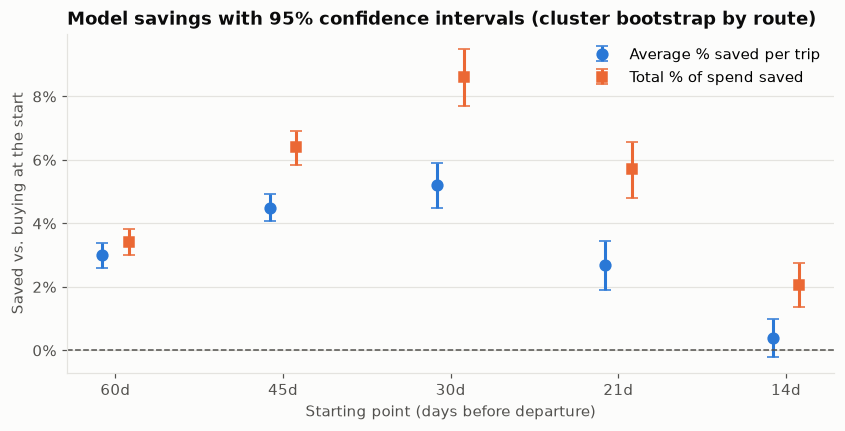

estimate                                                 \
metric avg_saved_pct avg_saved_usd share_lost_money total_saved_pct   
start                                                                 
60d            0.030         4.757            0.010           0.034   
45d            0.045         8.797            0.027           0.064   
30d            0.052        12.040            0.073           0.086   
21d            0.027         8.124            0.109           0.057   
14d            0.004         3.090            0.115           0.021   

         cluster_low                                                 \
metric avg_saved_pct avg_saved_usd share_lost_money total_saved_pct   
start                                                                 
60d            0.026         4.198            0.007           0.030   
45d            0.041         7.895            0.020           0.059   
30d            0.045        10.417            0.063           0.077   
21d            0.019         6.591            0.098           0.048   
14d           -0.002         1.990            0.104           0.014   

        cluster_high                                                 
metric avg_saved_pct avg_saved_usd share_lost_money total_saved_pct  
start                                                                
60d            0.034         5.313            0.015           0.038  
45d            0.049         9.721            0.035           0.069  
30d            0.059        13.804            0.083           0.095  
21d            0.035         9.683            0.122           0.065  
14d            0.010         4.193            0.127           0.027

In [4]:
fig, ax = plt.subplots()
for metric, color, marker, offset, label in [
        ("avg_saved_pct", SERIES[0], "o", -0.08, "Average % saved per trip"),
        ("total_saved_pct", SERIES[1], "s", 0.08, "Total % of spend saved")]:
    d = ci[ci.metric == metric].reset_index(drop=True)
    x = np.arange(len(d)) + offset
    ax.errorbar(x, d.estimate, yerr=[d.estimate - d.cluster_low, d.cluster_high - d.estimate],
                fmt=marker, color=color, markersize=7, capsize=4, linewidth=2, label=label)
ax.axhline(0, color=TEXT_MUTED, linewidth=1, linestyle="--")
ax.set_xticks(range(len(START_DAYS)), [f"{s}d" for s in START_DAYS])
ax.set_title("Model savings with 95% confidence intervals (cluster bootstrap by route)")
ax.set_xlabel("Starting point (days before departure)")
ax.set_ylabel("Saved vs. buying at the start")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax.legend(loc="upper right")
plt.show()

summary = ci.pivot(index="start", columns="metric", values=["estimate", "cluster_low", "cluster_high"])
summary = summary.reindex([f"{s}d" for s in START_DAYS])
summary.round(3)

- **Every interval from 21 to 60 days out sits clearly above zero.** The
  savings aren't a fluke of which trips happened to be in the sample.
- **From 14 days out, the interval (−0.2% to 1.0%) includes zero**, so I
  can't claim the model saves anything there. That fits notebook 04: with
  only two weeks left, the ceiling itself is small.
- **Total % is above average % at every starting point**, so the model
  saves more on expensive tickets (section 4 of the math reference).

## Pooled over starting points 30 to 60 days out

For a single headline, I pool every test trip that starts 30, 45 or 60 days
out. The same trip can appear at more than one starting point, which is one
more reason to cluster by route.

In [5]:
pool = pd.concat([results[s].assign(start=s) for s in (60, 45, 30)], ignore_index=True)
fare, pct = pool.start_fare.to_numpy(), pool.model_pct.to_numpy()
pooled = pd.DataFrame({"estimate": savings_stats(fare, pct)}).join(
    percentile_ci(bootstrap(fare, pct, clusters=pool.route.to_numpy(), n_boot=2000)))
pooled.round(4)

,estimate,low,high
avg_saved_pct,0.0450,0.0406,0.0494
total_saved_pct,0.0674,0.0618,0.0729
avg_saved_usd,9.3534,8.3506,10.4248
share_lost_money,0.0434,0.0363,0.0510


**This is the headline for my resume:** starting 30–60 days out, the model
saves **4.5% per trip (95% CI 4.1–4.9%)**, **6.7% of total spend (6.2–7.3%)**,
about **$9.35 per trip ($8.35–$10.42)**, and loses money on only **4.3%** of
trips.

## Does the model beat the simple rules? (paired comparison)

The fairest comparison puts two strategies on **the same trips** and looks
at the per-trip difference, $d_i = r_i^{\text{model}} - r_i^{\text{rule}}$.
Route effects that help or hurt both strategies cancel out, which makes the
comparison much sharper than comparing two separate averages.

- **vs. buy now:** the difference is just the model's savings (above).
- **vs. buy 21 days out:** only defined when starting more than 21 days out.
  Remember that notebook 05's honest walk-forward version of this rule
  picked "buy now". Here I give the simple rule the benefit of the doubt and
  use N = 21 directly.

In [6]:
rows = []
for s in (60, 45, 30):
    r = results[s]
    diff = (r.model_pct - r.buy21_pct).to_numpy()
    draws = bootstrap(np.ones(len(diff)), diff, clusters=r.route.to_numpy(), n_boot=2000)
    lo, hi = draws.avg_saved_pct.quantile([0.025, 0.975])
    rows.append({"start": f"{s}d", "model_pct": r.model_pct.mean(), "buy21_pct": r.buy21_pct.mean(),
                 "difference": diff.mean(), "ci_low": lo, "ci_high": hi,
                 "share_of_trips_model_better": (diff > 0).mean(),
                 "share_of_trips_rule_better": (diff < 0).mean()})
paired = pd.DataFrame(rows)
paired.round(4)

,start,model_pct,buy21_pct,difference,ci_low,ci_high,share_of_trips_model_better,share_of_trips_rule_better
0,60d,0.0299,0.0958,-0.0658,-0.0826,-0.0487,0.2747,0.5964
1,45d,0.0450,0.0209,0.0241,0.0120,0.0368,0.3756,0.4219
2,30d,0.0522,-0.0088,0.0611,0.0524,0.0698,0.4107,0.2645


- **30 days out:** the model beats "buy 21 days out" by **6.1 points**
  (CI 5.2–7.0). From 30 days out, blindly waiting until 21 days out usually
  doesn't pay, but the model knows when it does.
- **45 days out:** the model wins by **2.4 points** (CI 1.2–3.7).
- **60 days out:** the simple rule wins by **6.6 points** (CI 4.9–8.3), and
  is better on 60% of trips. From that far out the typical fare drifts down
  slowly for weeks, and a model that looks at most 21 days ahead buys too
  early. Two caveats: N = 21 was suggested by exploring this same data, so
  this comparison flatters the rule a little. And the fix is a strategy that
  plans over the whole window, which is the dynamic programming solver in
  notebook 07.

## Savings by fare band

Pooled over 30–60 days out:

In [7]:
pool["band"] = pd.cut(pool.start_fare, [0, 200, 500, np.inf],
                      labels=["under $200", "$200–500", "over $500"])
pool.groupby("band", observed=True).apply(
    lambda g: savings_stats(g.start_fare.to_numpy(), g.model_pct.to_numpy()).rename(None),
    include_groups=False).assign(trips=pool.groupby("band", observed=True).size()).round(3)

,avg_saved_pct,total_saved_pct,avg_saved_usd,share_lost_money,trips
band,,,,,
under $200,0.031,0.039,4.184,0.046,40464
$200–500,0.107,0.115,31.656,0.034,8274
over $500,0.190,0.192,108.270,0.012,249


The pattern from notebook 05 holds for the model too: **3% saved on
tickets under $200, 11% on $200–500 and 19% over $500** ($108 per trip).
Expensive starting fares have more room to fall, and the model recognizes
them. Most cheapest fares are under $200 (40k of 49k trips), which is why the
per-trip average is lower than the share of total spend.

## How much of the possible savings does the model capture?

In [8]:
pd.DataFrame({f"{s}d": {"model": r.model_pct.mean(), "hindsight ceiling": r.ceiling_pct.mean(),
                        "share captured": r.model_pct.mean() / r.ceiling_pct.mean()}
              for s, r in results.items()}).T.round(3)

,model,hindsight ceiling,share captured
60d,0.030,0.303,0.099
45d,0.045,0.230,0.195
30d,0.052,0.180,0.290
21d,0.027,0.136,0.199
14d,0.004,0.083,0.048


Even the best case captures under a third of what perfect hindsight
would. That's expected, since the ceiling assumes I know the future. It also
shows how much room is left for better strategies (notebooks 07 and 08).

## Resume bullet

> Built a buy-or-wait flight purchasing model on 82M Expedia fare records,
> framing purchase timing as an optimal-stopping problem; a walk-forward
> backtest over ~49K trip decisions showed **4.5% average savings per trip
> (6.7% of total spend)** vs. a buy-now baseline (95% route-clustered
> bootstrap CI: 4.1–4.9%), with only 4% of trips losing money.